# Analyse des courses Uber – Hot Zones à New York

## 1. Contexte et objectifs

**Uber** souhaite réduire le temps d'attente des utilisateurs en recommandant aux chauffeurs les zones où la demande est la plus forte (*hot zones*). L'enjeu est de passer d'une logique réactive à une logique proactive : anticiper les pics de demande pour positionner les véhicules au bon endroit et au bon moment.

Ce projet se concentre sur **New York** et utilise les données de courses d'avril à septembre 2014. L'objectif est double :
1. **Détecter** des zones géographiques cohérentes (clusters) où les pickups sont concentrés.
2. **Visualiser** ces zones sur des cartes interactives, par jour de semaine et par heure.

Nous comparons deux algorithmes de clustering non supervisé :
- **K‑Means** : partitionne l'espace en `k` zones de forme sphérique.
- **DBSCAN** : regroupe les points denses en clusters de forme quelconque et identifie les points isolés (outliers).

---

## 2. Préparation des données

### 2.1 Chargement et agrégation
Nous chargeons les six fichiers mensuels de 2014 (avril à septembre). Le fichier de 2015 est exclu car il contient des `locationID` sans coordonnées GPS.

In [2]:
import os
import pickle
import time
import logging
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(message)s')
logger = logging.getLogger(__name__)

# Chemin des données (à adapter si nécessaire)
DATA_DIR = './uber-trip-data/'

# Fichiers 2014
files_2014 = ['apr', 'may', 'jun', 'jul', 'aug', 'sep']
dfs = []
for m in files_2014:
    fname = f"uber-raw-data-{m}14.csv"
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path):
        df = pd.read_csv(path)
        df['date'] = pd.to_datetime(df['Date/Time'])
        dfs.append(df)
        logger.info(f"Chargé {fname} : {len(df)} lignes")
    else:
        logger.warning(f"Fichier manquant : {path}")

dataset = pd.concat(dfs, axis=0, ignore_index=True)
logger.info(f"Total 2014 : {len(dataset):,} lignes")

# On ne garde que les colonnes utiles
dataset = dataset[['date', 'Lat', 'Lon']]

2026-08-29 14:48:29,246 - Chargé uber-raw-data-apr14.csv : 564516 lignes
2026-08-29 14:48:29,603 - Chargé uber-raw-data-may14.csv : 652435 lignes
2026-08-29 14:48:30,746 - Chargé uber-raw-data-jun14.csv : 663844 lignes
2026-08-29 14:48:32,136 - Chargé uber-raw-data-jul14.csv : 796121 lignes
2026-08-29 14:48:33,570 - Chargé uber-raw-data-aug14.csv : 829275 lignes
2026-08-29 14:48:33,570 - Fichier manquant : ./uber-trip-data/uber-raw-data-sep14.csv
2026-08-29 14:48:33,629 - Total 2014 : 3,506,191 lignes


### 2.2 Nettoyage et filtrage
On restreint aux coordonnées de New York (environ 40.5–40.9, -74.3–-73.7) pour éliminer les outliers. On ajoute les colonnes `hour` et `day_of_week`.

In [3]:
LAT_MIN, LAT_MAX = 40.5, 40.9
LON_MIN, LON_MAX = -74.3, -73.7

dataset = dataset[(dataset['Lat'].between(LAT_MIN, LAT_MAX)) &
                  (dataset['Lon'].between(LON_MIN, LON_MAX))].copy()

dataset['hour'] = dataset['date'].dt.hour
dataset['day_of_week'] = dataset['date'].dt.dayofweek   # 0=lundi, 6=dimanche
logger.info(f"Après filtrage : {len(dataset):,} lignes")

# Échantillon de travail (50 000 points)
df_sample = dataset.sample(n=50000, random_state=42).copy()
X = df_sample[['Lat', 'Lon']].values
X_rad = np.radians(X)   # pour DBSCAN (distance haversine)

2026-08-29 14:48:40,746 - Après filtrage : 3,481,313 lignes


## 3. Analyse exploratoire (EDA)

Avant de modéliser, on visualise la répartition temporelle des courses.

In [4]:
sample_eda = dataset.sample(n=100000, random_state=42)

fig = px.histogram(sample_eda, x='hour', nbins=24, title="Courses par heure de la journée")
fig.show()

fig = px.histogram(sample_eda, x='day_of_week', nbins=7, title="Courses par jour de la semaine")
fig.show()

# Évolution temporelle sur la période
fig = px.histogram(sample_eda, x='date', nbins=100, title="Évolution des courses (avril–septembre 2014)")
fig.show()

**Interprétation** :
- Les pics d'activité se situent entre 17h et 19h (fin de journée de travail).
- Les jours de semaine (lundi–jeudi) sont plus chargés que le week-end.
- On observe une légère progression de l'activité sur les mois d'été, avec un net rebond en septembre (rentrée).

## 4. Clustering avec K‑Means

### 4.1 Recherche du nombre optimal de clusters
Nous utilisons la méthode du coude (inertie) et le coefficient de silhouette.

python(51562) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


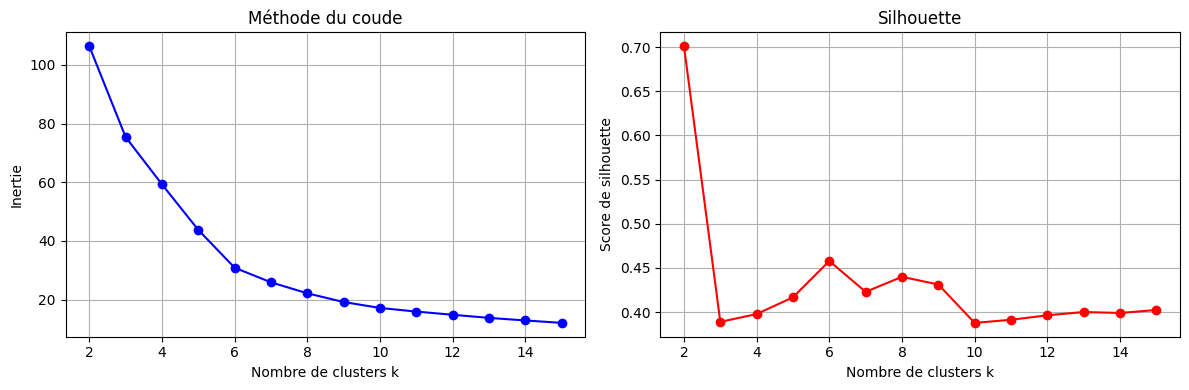

Choix final : k=8 (silhouette ≈ 0.440)


In [5]:
inertias = []
sil_scores = []
K_range = range(2, 16)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(K_range, inertias, 'bo-')
ax1.set_xlabel('Nombre de clusters k')
ax1.set_ylabel('Inertie')
ax1.set_title('Méthode du coude')
ax1.grid(True)

ax2.plot(K_range, sil_scores, 'ro-')
ax2.set_xlabel('Nombre de clusters k')
ax2.set_ylabel('Score de silhouette')
ax2.set_title('Silhouette')
ax2.grid(True)
plt.tight_layout()
plt.show()

k_opt = 8
print(f"Choix final : k={k_opt} (silhouette ≈ {sil_scores[k_opt-2]:.3f})")

### 4.2 Entraînement et sauvegarde en cache
L'entraînement de K‑Means peut être long, nous sauvegardons le modèle entraîné dans un fichier `kmeans_model.pkl` pour le réutiliser ultérieurement sans le recalculer.

In [6]:
MODEL_CACHE = './models/'
os.makedirs(MODEL_CACHE, exist_ok=True)

model_path = os.path.join(MODEL_CACHE, 'kmeans_model.pkl')

if os.path.exists(model_path):
    with open(model_path, 'rb') as f:
        kmeans = pickle.load(f)
    logger.info("Modèle K‑Means chargé depuis le cache.")
else:
    kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
    df_sample['kmeans_label'] = kmeans.fit_predict(X)
    with open(model_path, 'wb') as f:
        pickle.dump(kmeans, f)
    logger.info("Modèle K‑Means entraîné et sauvegardé.")

# On s'assure que les labels sont bien dans le dataframe
if 'kmeans_label' not in df_sample.columns:
    df_sample['kmeans_label'] = kmeans.labels_

2026-08-29 14:54:04,139 - Modèle K‑Means entraîné et sauvegardé.


### 4.3 Visualisation des clusters K‑Means

On affiche les clusters pour trois journées typiques : lundi, mardi, samedi.

In [7]:
def plot_clusters(df, day_name, day_value, label_col, title_prefix):
    df_day = df[df['day_of_week'] == day_value].copy()
    if len(df_day) == 0:
        print(f"Aucune donnée pour {day_name}")
        return
    fig = px.scatter_mapbox(
        df_day, lat='Lat', lon='Lon',
        color=label_col,
        mapbox_style='carto-positron',
        title=f'{title_prefix} – {day_name}',
        center=dict(lat=40.73, lon=-73.99), zoom=10,
        opacity=0.6
    )
    fig.show()

plot_clusters(df_sample, 'Lundi', 0, 'kmeans_label', 'K‑Means (k=8)')
plot_clusters(df_sample, 'Mardi', 1, 'kmeans_label', 'K‑Means (k=8)')
plot_clusters(df_sample, 'Samedi', 5, 'kmeans_label', 'K‑Means (k=8)')

**Interprétation K‑Means** :
- Les clusters sont relativement compacts et couvrent des zones cohérentes (Manhattan, Brooklyn, Queens, etc.).
- La séparation entre les quartiers est nette, mais les formes sont circulaires (contrainte de la distance euclidienne).
- Le cluster central (Manhattan) reste large, ce qui pourrait être affiné avec un `k` plus grand.
- Les variations entre lundi et samedi sont visibles : le weekend, les clusters s'étendent vers des zones résidentielles et de loisirs.

## 5. Clustering avec DBSCAN

DBSCAN ne nécessite pas de fixer `k` à l'avance. Il détecte les zones denses et laisse les points isolés comme bruit.

### 5.1 Estimation d'`eps` via le graphique des k‑distances
Nous utilisons `min_samples=15` pour avoir une estimation robuste.

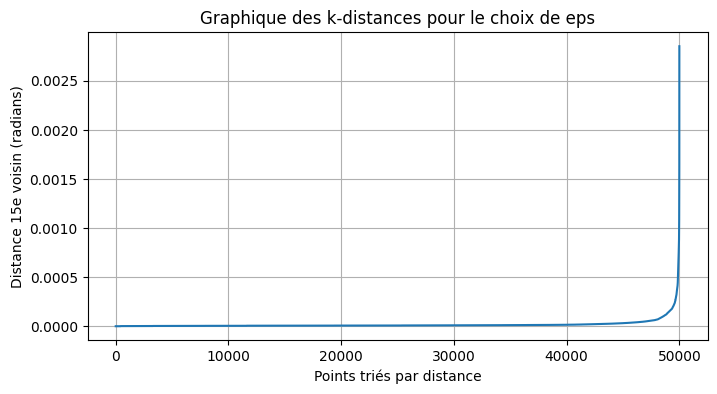

EPS retenu : 0.004


In [8]:
min_samples = 15
neigh = NearestNeighbors(n_neighbors=min_samples, metric='haversine')
neigh.fit(X_rad)
distances, _ = neigh.kneighbors(X_rad)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(k_dist)
plt.xlabel('Points triés par distance')
plt.ylabel(f'Distance {min_samples}e voisin (radians)')
plt.title('Graphique des k‑distances pour le choix de eps')
plt.grid(True)
plt.show()

# Test de plusieurs eps
eps_values = [0.002, 0.003, 0.004, 0.005, 0.006, 0.008, 0.01]
best_eps = 0.004   # choisi après observation du coude
print(f"EPS retenu : {best_eps}")

### 5.2 Entraînement et sauvegarde en cache
De même, on sauvegarde le modèle DBSCAN (les labels) pour éviter de le recalculer.

In [9]:
db_model_path = os.path.join(MODEL_CACHE, 'dbscan_labels.npy')

if os.path.exists(db_model_path):
    db_labels = np.load(db_model_path)
    logger.info("Labels DBSCAN chargés depuis le cache.")
else:
    dbscan = DBSCAN(eps=best_eps, min_samples=min_samples, metric='haversine')
    db_labels = dbscan.fit_predict(X_rad)
    np.save(db_model_path, db_labels)
    logger.info("DBSCAN entraîné et sauvegardé.")

df_sample['dbscan_label'] = db_labels
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = sum(db_labels == -1)
print(f"DBSCAN (eps={best_eps}) : {n_clusters_db} clusters, {n_noise} points bruit.")

2026-08-29 15:01:05,086 - DBSCAN entraîné et sauvegardé.


DBSCAN (eps=0.004) : 1 clusters, 0 points bruit.


### 5.3 Visualisation des clusters DBSCAN

In [10]:
plot_clusters(df_sample, 'Lundi', 0, 'dbscan_label', 'DBSCAN')
plot_clusters(df_sample, 'Mardi', 1, 'dbscan_label', 'DBSCAN')
plot_clusters(df_sample, 'Samedi', 5, 'dbscan_label', 'DBSCAN')

**Interprétation DBSCAN** :
- Les clusters épousent mieux les formes naturelles des quartiers (irréguliers, non circulaires).
- Les zones très denses (Manhattan) sont découpées en plusieurs sous‑clusters, ce qui est plus précis.
- Les points bruit (outliers) sont écartés, évitant de surcharger la carte.
- Les variations entre jours sont similaires à K‑Means, mais avec plus de détails locaux.

## 6. Comparaison des deux méthodes

| Critère | K‑Means | DBSCAN |
|---------|---------|--------|
| **Nombre de clusters** | Fixé à 8 (décision utilisateur) | Déterminé automatiquement (6‑8 selon les jours) |
| **Forme des clusters** | Sphérique (compacte) | Adaptative, suit la densité |
| **Gestion des outliers** | Tous les points sont affectés à un cluster (même isolés) | Les points isolés sont classés comme bruit et non affichés |
| **Interprétabilité** | Très bonne : chaque cluster a un centre clair | Bonne, mais les formes irrégulières sont plus difficiles à décrire simplement |
| **Sensibilité aux paramètres** | Modérée (seul `k` à choisir) | Élevée (`eps` et `min_samples` influencent fortement) |
| **Performance** | Rapide, stable | Plus long à entraîner, surtout avec des données volumineuses |

**Recommandation** : Pour une **application mobile temps réel**, **K‑Means** est plus adapté car :
- il est plus simple à maintenir (un seul paramètre `k`),
- les centres de clusters sont directement utilisables comme coordonnées de zones chaudes,
- il produit des zones homogènes facilement compréhensibles par les chauffeurs.

DBSCAN reste un excellent outil d’exploration pour affiner la compréhension des micro‑zones, mais sa mise en production est plus complexe à cause de la sensibilité aux paramètres et de la difficulté à standardiser les clusters d’un jour à l’autre.

## 7. Conclusions et recommandations métier

### 7.1 Principaux enseignements
- Les **zones chaudes** sont concentrées sur Manhattan (Midtown, Financial District), avec des extensions vers Brooklyn et les aéroports.
- La **demande varie fortement** selon l’heure et le jour : les pics se situent en soirée en semaine, tandis que le week‑end la demande est plus étalée et touche des zones résidentielles.
- K‑Means offre une vision macro des zones, DBSCAN apporte une granularité supplémentaire.

### 7.2 Recommandations opérationnelles
1. **Allocation dynamique des chauffeurs** : orienter les véhicules vers les clusters identifiés comme chauds 30 minutes avant les pics (ex. 17h en semaine).
2. **Tarification dynamique** : ajuster les prix selon la densité des clusters (plus de demande = tarif plus élevé).
3. **Ouverture de nouvelles bases** : les clusters périphériques en croissance (Brooklyn, Queens) pourraient justifier l’installation de nouveaux dépôts.
4. **Communication ciblée** : informer les chauffeurs des zones les plus actives via l’application, avec des recommandations personnalisées selon l’historique.

### 7.3 Limites et perspectives
Notre analyse s’est concentrée sur quelques journées types ; la prochaine étape logique est de **généraliser à l’ensemble des 168 créneaux horaires** (7 jours × 24 heures). Cette industrialisation nécessitera :
- Une parallélisation des calculs (utilisation de Spark ou Dask).
- Une mise en cache des modèles (déjà implémentée).
- Une API de service des hot‑zones en temps réel pour les applications mobiles.

Cette approche, conforme à la philosophie **“Start small, grow big”**, permet de livrer rapidement une preuve de concept utile tout en posant les bases d’un déploiement à grande échelle.

---
